## Analysing snippets

In [21]:
import pandas as pd
from driver import clean_text, get_text_stats
import numpy as np
import re

results_navigation = pd.read_csv("Data/results_navigation.csv")
results_navigation["timestamp"] = pd.to_datetime(results_navigation["timestamp"])

results_navigation["snippet"] = results_navigation["snippet"].apply(lambda x: clean_text(x))
# results_navigation["snippet"] = results_navigation["snippet"].apply(lambda x: re.sub(
#     r'^(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Sept|Oct|Nov|Dec)\s+\d{1,2},\s+\d{4}\s*(?:\.\.\.)?\s*',
#     '',
#     x,
#     flags=re.IGNORECASE
# ))
results_navigation["snippet"] = results_navigation["snippet"].apply(lambda x: x.strip())
results_navigation["SERP_result"] = [str(title).strip()+snippet for title, snippet in zip(results_navigation["title"], results_navigation["snippet"])]

text_stat_results = get_text_stats(results_navigation, "SERP_result")

results_navigation["SERP_result_content_len"] = text_stat_results["content_len"]
results_navigation["SERP_result_mean_aoa"] = text_stat_results["mean_aoa"]
results_navigation["SERP_result_mean_conc"] = text_stat_results["mean_conc"]
results_navigation["SERP_result_gulpease_index"] = text_stat_results["gulpease_index"]
# results_navigation["snippet_fres"] = text_stat_results["fres"]

  0%|          | 0/930 [00:00<?, ?it/s]

In [22]:
results_navigation.to_csv("Data/results_navigation.csv", index=False, encoding='utf8')

In [23]:
results_navigation.loc[pd.isna(results_navigation["rank"])]

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp,SERP_result,SERP_result_content_len,SERP_result_mean_aoa,SERP_result_mean_conc,SERP_result_gulpease_index


## Analysing navigation

In [24]:
import pandas as pd

# nlp = spacy.load("it_core_news_lg")
navigation_quality = pd.read_csv("Data/navigation_quality.csv")
navigation_quality["last_relevant_timestamp"] = pd.to_datetime(navigation_quality["last_relevant_timestamp"])
navigation_quality["effective_nav"] = [int(nav_eff >= 0.8) for nav_eff in navigation_quality["nav_eff"]]

tail_ratio = []
for i, row in navigation_quality.iterrows():
    if row["total_clicks"] > 0:
        tail_ratio.append(row["tail"]/row["total_clicks"])
    else:
        tail_ratio.append(None)
navigation_quality["tail_ratio"] = tail_ratio
navigation_quality["effective_nav_pt2"] = [int(tail_ratio<0.2) for tail_ratio in navigation_quality["tail_ratio"]]
navigation_quality.to_csv("Data/navigation_quality.csv", index=False, encoding="utf8")

serp_df = pd.read_csv("Data/results_navigation.csv")

query_df = pd.read_csv("Data/query_df.csv")
query_df["timestamp"] = pd.to_datetime(query_df["timestamp"])

click_df = pd.read_csv("Data/clicked_results_df.csv")
click_df["timestamp"] = pd.to_datetime(click_df["timestamp"])

view_df = pd.read_csv("Data/viewed_results_df.csv")
view_df["timestamp"] = pd.to_datetime(view_df["timestamp"])
view_df["associated_click_timestamp"] = pd.to_datetime(view_df["associated_click_timestamp"])

In [25]:
view_df.head()

,uid,topic_number,query,url,rank,viewType,viewDurationInSeconds,timestamp,serp_id,associated_click_timestamp
0,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,resultExposureStarted,NaN,2026-05-19 14:51:27.960,serp1,2026-05-19 14:51:43.444
1,1,g3t3,Quali sono i cinque animali tipici dell india,https://www.terreincognitemagazine.it/natura-s...,2,resultExposureStarted,NaN,2026-05-19 14:51:27.966,serp1,2026-05-19 14:51:43.444
2,1,g3t3,Quali sono i cinque animali tipici dell india,https://www.storicang.it/a/civilta-dellindo-i-...,3,resultExposureStarted,NaN,2026-05-19 14:51:31.168,serp1,2026-05-19 14:51:43.444
3,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,resultExposureEnded,15.730,2026-05-19 14:51:43.438,serp1,2026-05-19 14:51:43.444
4,1,g3t3,Quali sono i cinque animali tipici dell india,https://www.terreincognitemagazine.it/natura-s...,2,resultExposureEnded,15.731,2026-05-19 14:51:43.440,serp1,2026-05-19 14:51:43.444


In [26]:
serp_df.head()

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp,SERP_result,SERP_result_content_len,SERP_result_mean_aoa,SERP_result_mean_conc,SERP_result_gulpease_index
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://wwftravel.it/blog/viaggi/india-natura-...,"India naturalistica, 5 animali da non perdere ...","Oct 31, 2023 ... La fauna selvatica dell'India...",1,1,2,2026-05-19 14:51:27.687,"India naturalistica, 5 animali da non perdere ...",34,6.270000,7.875000,58.022989
1,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.terreincognitemagazine.it/natura-s...,"Natura selvaggia in India, tra tigri e leoni -...","Feb 17, 2017 ... O dei Giganti, vista la mole ...",2,1,0,2026-05-19 14:51:27.688,"Natura selvaggia in India, tra tigri e leoni -...",36,6.864000,5.666667,66.250000
2,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.storicang.it/a/civilta-dellindo-i-...,"La civiltà dell'Indo, i misteri di un popolo d...","Jun 5, 2023 ... Sono note cinque metropoli, tr...",3,0,0,2026-05-19 14:51:27.689,"La civiltà dell'Indo, i misteri di un popolo d...",32,NaN,NaN,65.363636
3,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.focusjunior.it/scuola/storia/chi-s...,"Chi sono gli Indiani d'America, i nativi ameri...","Jun 6, 2024 ... Chi sono, da dove vengono e qu...",4,0,0,2026-05-19 14:51:27.690,"Chi sono gli Indiani d'America, i nativi ameri...",33,NaN,NaN,61.536765
4,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.focusjunior.it/comportamento/feste...,Festa della mamma: come si festeggia nel resto...,Il dolce tipico per celebrare questo giorno è ...,5,0,0,2026-05-19 14:51:27.691,Festa della mamma: come si festeggia nel resto...,37,3.914286,7.200000,64.444015


In [27]:
(query_df["timestamp"].max() - query_df["timestamp"].min()).total_seconds()

17030.947

In [28]:
query_df["timestamp"].mean()

Timestamp('2026-05-19 13:09:04.049101824')

In [29]:
view_temp_df = view_df.loc[(view_df["serp_id"]=="serp10") & (view_df["viewType"]=="resultExposureEnded")]
view_temp_df["rank"].value_counts(), view_temp_df["rank"].value_counts().mean()

(rank
 1    2
 2    2
 3    2
 7    1
 6    1
 5    1
 4    1
 Name: count, dtype: int64,
 np.float64(1.4285714285714286))

In [30]:
import numpy as np

first_click_time = [] # time from query entry to first click
avg_scroll_time_before_click = [] # how much time is spent scrolling on SERP before a click
# avg_snippet_dwell_time = [] # average time for which a snippet is viewed at a time 
rank_lowest_view = [] # rank of the lowest viewed result
avg_snippet_view_counts_before_click = [] # average number of times a user views a snippet before making a click
avg_snippet_dwell_time_before_click = [] # average time a user dwells on a snippet before scrolling prior to making a click

SERP_avg_aoa = []
SERP_avg_conc = []
SERP_avg_length = []
SERP_avg_gulpease_index = []

viewed_avg_aoa = []
viewed_avg_conc = []
viewed_avg_length = []
viewed_avg_gulpease_index = []

for serp_id in navigation_quality["serp_id"]:
    query_temp_df = query_df.loc[query_df["serp_id"] == serp_id]
    click_temp_df = click_df.loc[click_df["serp_id"] == serp_id]
    serp_temp_df = serp_df.loc[serp_df["serp_id"]==serp_id]
    view_temp_df = view_df.loc[(view_df["serp_id"]==serp_id) & (view_df["viewType"]=="resultExposureEnded")]

    first_click_time.append((click_temp_df["timestamp"].min() - query_temp_df["timestamp"].min()).total_seconds())
    rank_lowest_view.append(view_temp_df["rank"].max())

    scroll_time_before_click = []
    snippet_dwell_time_before_scroll = []
    avg_snippet_view_counts = []

    for _, click in click_temp_df.iterrows():
        views_before_click = view_temp_df.loc[view_temp_df["associated_click_timestamp"]==click["timestamp"]]
        # print(serp_id, click["timestamp"], len(views_before_click))
        
        scroll_time_before_click.append((click["timestamp"] - views_before_click["timestamp"].min()).total_seconds())
        snippet_dwell_time_before_scroll.append(np.mean(views_before_click["viewDurationInSeconds"]))
        avg_snippet_view_counts.append(views_before_click["rank"].value_counts().mean())

    avg_scroll_time_before_click.append(np.mean(scroll_time_before_click))
    avg_snippet_dwell_time_before_click.append(np.mean(snippet_dwell_time_before_scroll))
    avg_snippet_view_counts_before_click.append(np.mean(avg_snippet_view_counts))

    # if len(click_temp_df) <= 1:
    #     avg_dwell_time_before_click.append(0)
    # else:
    #     click_temp_df = click_df.loc[click_df["serp_id"] == serp_id]

    #     for i, clicks in click_temp_df[1:].iterrows():
    #         time_before_click.append((click_temp_df.iloc[i]["timestamp"]- click_temp_df.iloc[i-1]["timestamp"]).total_seconds())
    #     avg_dwell_time_before_click.append(np.mean(time_before_click))

    SERP_avg_aoa.append(pd.Series([aoa for aoa in serp_temp_df["SERP_result_mean_aoa"]]).mean())
    SERP_avg_conc.append(pd.Series([conc for conc in serp_temp_df["SERP_result_mean_conc"]]).mean())
    SERP_avg_gulpease_index.append(pd.Series([gulp_ind for gulp_ind in serp_temp_df["SERP_result_gulpease_index"]]).mean())
    SERP_avg_length.append(pd.Series([cont_len for cont_len in serp_temp_df["SERP_result_content_len"]]).mean())

    viewed_avg_aoa.append(pd.Series([serp_temp_df.loc[serp_temp_df["url"]==url]["SERP_result_mean_aoa"].values[0] for url in view_temp_df["url"].unique()]).mean())
    viewed_avg_conc.append(pd.Series([serp_temp_df.loc[serp_temp_df["url"]==url]["SERP_result_mean_conc"].values[0] for url in view_temp_df["url"].unique()]).mean())
    viewed_avg_length.append(pd.Series([serp_temp_df.loc[serp_temp_df["url"]==url]["SERP_result_content_len"].values[0] for url in view_temp_df["url"].unique()]).mean())
    viewed_avg_gulpease_index.append(pd.Series([serp_temp_df.loc[serp_temp_df["url"]==url]["SERP_result_gulpease_index"].values[0] for url in view_temp_df["url"].unique()]).mean())

navigation_quality["first_click_time"] = first_click_time
navigation_quality["avg_scroll_time_before_click"] = avg_scroll_time_before_click
navigation_quality["avg_snippet_dwell_time_before_click"] = avg_snippet_dwell_time_before_click
navigation_quality["avg_snippet_view_counts_before_click"] = avg_snippet_view_counts_before_click
navigation_quality["rank_lowest_view"] = rank_lowest_view

navigation_quality["viewed_avg_aoa"] = viewed_avg_aoa
navigation_quality["viewed_avg_conc"] = viewed_avg_conc
navigation_quality["viewed_avg_length"] = viewed_avg_length
navigation_quality["viewed_avg_gulpease_index"] = viewed_avg_gulpease_index

navigation_quality["SERP_avg_aoa"] = SERP_avg_aoa
navigation_quality["SERP_avg_conc"] = SERP_avg_conc
navigation_quality["SERP_avg_gulpease_index"] = SERP_avg_gulpease_index
navigation_quality["SERP_avg_length"] = SERP_avg_length

navigation_quality["last_relevant_timestamp"] = pd.to_datetime(navigation_quality["last_relevant_timestamp"])
navigation_quality.to_csv("Data/navigation_quality.csv", index=False, encoding="utf8")

c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtyp

In [31]:
navigation_quality.head()

,uid,topic_number,qid,query,serp_id,total_clicks,repetitions,tail,last_relevant_timestamp,nav_eff,...,viewed_avg_aoa,viewed_avg_conc,viewed_avg_length,viewed_avg_gulpease_index,SERP_avg_aoa,SERP_avg_conc,SERP_avg_gulpease_index,SERP_avg_length,tail_ratio,effective_nav_pt2
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,2,1,0,2026-05-19 14:53:19.408,0.5,...,5.632918,6.431042,33.900000,66.377603,5.632918,6.431042,66.377603,33.900,0.0,1
1,1,g3t2,q2,Quale è il nome del simbolo al centro della ba...,serp2,1,0,0,2026-05-19 15:02:48.776,1.0,...,4.690000,6.150000,32.000000,61.852665,4.690000,6.150000,61.852665,32.000,0.0,1
2,1,g3t1,q3,Fiume sacro degli indiani,serp3,1,0,0,2026-05-19 15:08:58.405,1.0,...,4.775000,7.241667,37.500000,47.423141,4.974583,7.119792,55.810356,34.625,0.0,1
3,2,g3t3,q4,Quali sono i animali dall'India,serp4,0,0,0,NaT,NaN,...,4.723333,7.862500,35.000000,78.369688,5.252222,6.732812,64.844950,31.600,NaN,0
4,2,g3t3,q5,Quali sono i 5 animali tipici dall'India,serp5,1,0,0,2026-05-19 14:52:53.759,1.0,...,6.322413,6.267333,32.857143,69.293081,5.786159,6.757083,69.356585,33.700,0.0,1


## Visualisation

In [32]:
import pandas as pd

navigation_quality = pd.read_csv("Data/navigation_quality.csv")
categories = [
    "first_click_time", "avg_scroll_time_before_click", "avg_snippet_dwell_time_before_click", "avg_snippet_view_counts_before_click", "rank_lowest_view", 
    "viewed_avg_length", "viewed_avg_gulpease_index", "viewed_avg_conc", "viewed_avg_aoa",
    # "SERP_avg_length", "SERP_avg_gulpease_index", "SERP_avg_conc", "SERP_avg_aoa"
]
# navigation_quality

In [33]:
len(navigation_quality.loc[navigation_quality["effective_nav_pt2"]==1]), len(navigation_quality)

(47, 103)

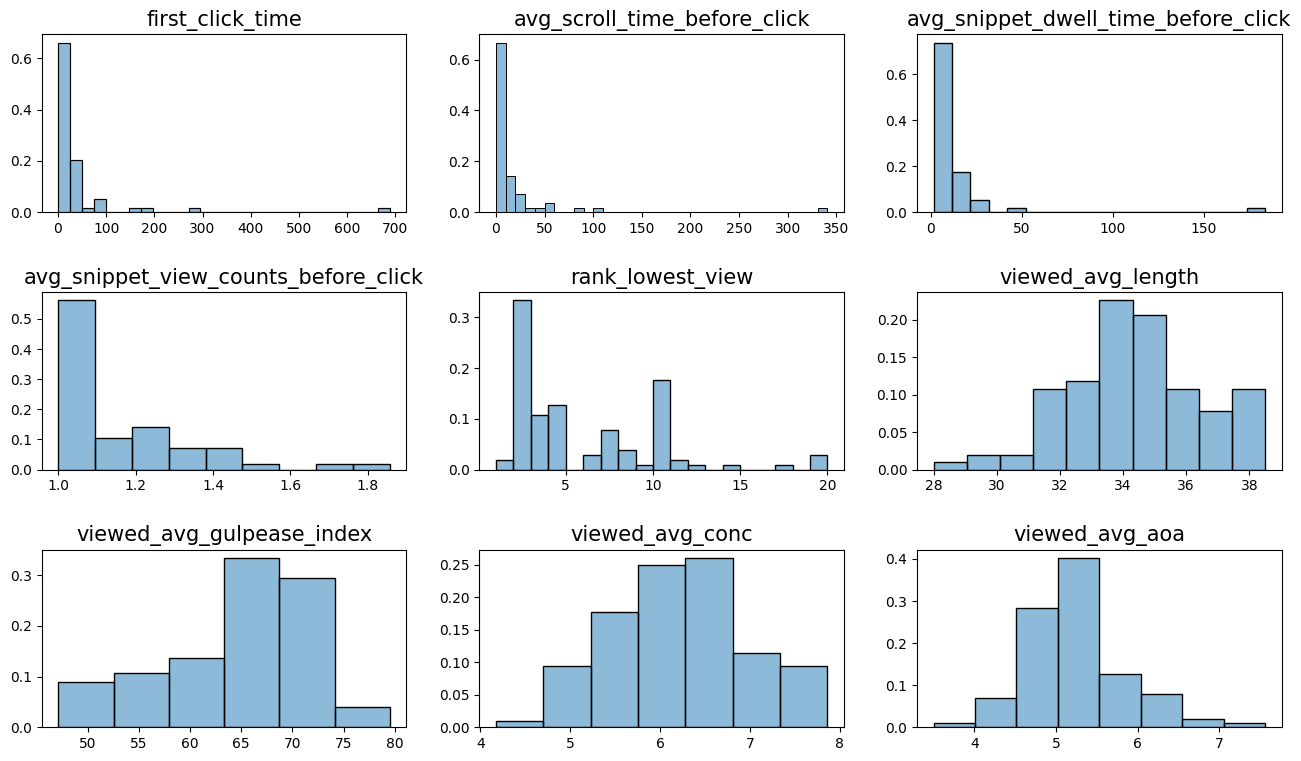

,category,mean,std_dev,max,min,median,modes
0,first_click_time,42.960610,98.420228,688.605000,0.752000,18.880000,"[0.752, 1.442, 3.171, 3.369, 4.61, 5.424, 5.73..."
1,avg_scroll_time_before_click,18.623926,48.068321,341.061000,0.002000,7.046200,[0.003]
2,avg_snippet_dwell_time_before_click,12.583515,24.504127,183.789667,1.574333,6.613229,"[1.5743333333333334, 1.77, 3.3635, 3.619744444..."
3,avg_snippet_view_counts_before_click,1.142713,0.188576,1.857143,1.000000,1.052778,[1.0]
4,rank_lowest_view,5.617647,4.286853,20.000000,1.000000,4.000000,[2.0]
5,viewed_avg_length,34.324192,2.100911,38.500000,28.000000,34.292857,"[34.0, 35.0]"
6,viewed_avg_gulpease_index,64.878921,7.192167,79.525876,47.114628,66.920593,[70.00657894736842]
7,viewed_avg_conc,6.205167,0.761402,7.862500,4.175000,6.249722,[5.578124999999999]
8,viewed_avg_aoa,5.251159,0.595631,7.560000,3.500000,5.192867,[4.6]


In [34]:
import pandas as pd
from driver import get_descriptive_stats

results_navigation = pd.read_csv("Data/navigation_quality.csv")
categories = [
    # "total_clicks", "repetitions", 
    "first_click_time", "avg_scroll_time_before_click", "avg_snippet_dwell_time_before_click", "avg_snippet_view_counts_before_click", "rank_lowest_view", 
    "viewed_avg_length", "viewed_avg_gulpease_index", "viewed_avg_conc", "viewed_avg_aoa",
    # "SERP_avg_length", "SERP_avg_gulpease_index", "SERP_avg_conc", "SERP_avg_aoa"
]

binwidth_map = {
    "first_click_time": 25,
    "avg_scroll_time_before_click": 10,
    "avg_snippet_dwell_time_before_click": 10,
    "avg_snippet_view_counts_before_click": 0.1,
    "rank_lowest_view": 1,
    "viewed_avg_length": 1,
    "viewed_avg_gulpease_index": 5,
    "viewed_avg_conc": 0.5,
    "viewed_avg_aoa": 0.5

}

desc_stats = get_descriptive_stats(df=results_navigation, search_stage="results_navigation", categories=categories, ncols=3, nrows=3, binwidth_map=binwidth_map)
desc_stats

In [35]:
from driver import get_significance

desc_stats_df_nav_eff, sig_test_results_nav_eff = get_significance(df=navigation_quality, effective_label="effective_nav", search_stage="results_navigation_nav_eff", categories=categories)
sig_test_results_nav_eff

,search_stage,characteristic,test_statistic,pval,significant
0,results_navigation_nav_eff,first_click_time,-2.482500,0.4476,False
1,results_navigation_nav_eff,avg_scroll_time_before_click,-0.171850,0.9426,False
2,results_navigation_nav_eff,avg_snippet_dwell_time_before_click,-1.411440,0.3088,False
3,results_navigation_nav_eff,avg_snippet_view_counts_before_click,0.083333,0.2110,False
4,results_navigation_nav_eff,rank_lowest_view,0.000000,1.0000,False
5,results_navigation_nav_eff,viewed_avg_length,0.014286,0.9796,False
6,results_navigation_nav_eff,viewed_avg_gulpease_index,3.452140,0.0414,True
7,results_navigation_nav_eff,viewed_avg_conc,-0.367500,0.0676,False
8,results_navigation_nav_eff,viewed_avg_aoa,0.091733,0.2926,False


In [36]:
desc_stats_df_nav_eff

,search_stage,characteristic,ineffective_median,ineffective_MAD,effective_median,effective_MAD
0,results_navigation_nav_eff,first_click_time,16.861000,9.532000,19.343500,11.990500
1,results_navigation_nav_eff,avg_scroll_time_before_click,7.046200,5.683000,7.218050,7.210550
2,results_navigation_nav_eff,avg_snippet_dwell_time_before_click,5.452750,1.790650,6.864190,2.954918
3,results_navigation_nav_eff,avg_snippet_view_counts_before_click,1.083333,0.083333,1.000000,0.000000
4,results_navigation_nav_eff,rank_lowest_view,4.000000,2.000000,4.000000,2.000000
5,results_navigation_nav_eff,viewed_avg_length,34.300000,1.200000,34.285714,1.214286
6,results_navigation_nav_eff,viewed_avg_gulpease_index,67.940139,3.254063,64.487999,4.815019
7,results_navigation_nav_eff,viewed_avg_conc,6.000000,0.529167,6.367500,0.227083
8,results_navigation_nav_eff,viewed_avg_aoa,5.251733,0.381185,5.160000,0.222500


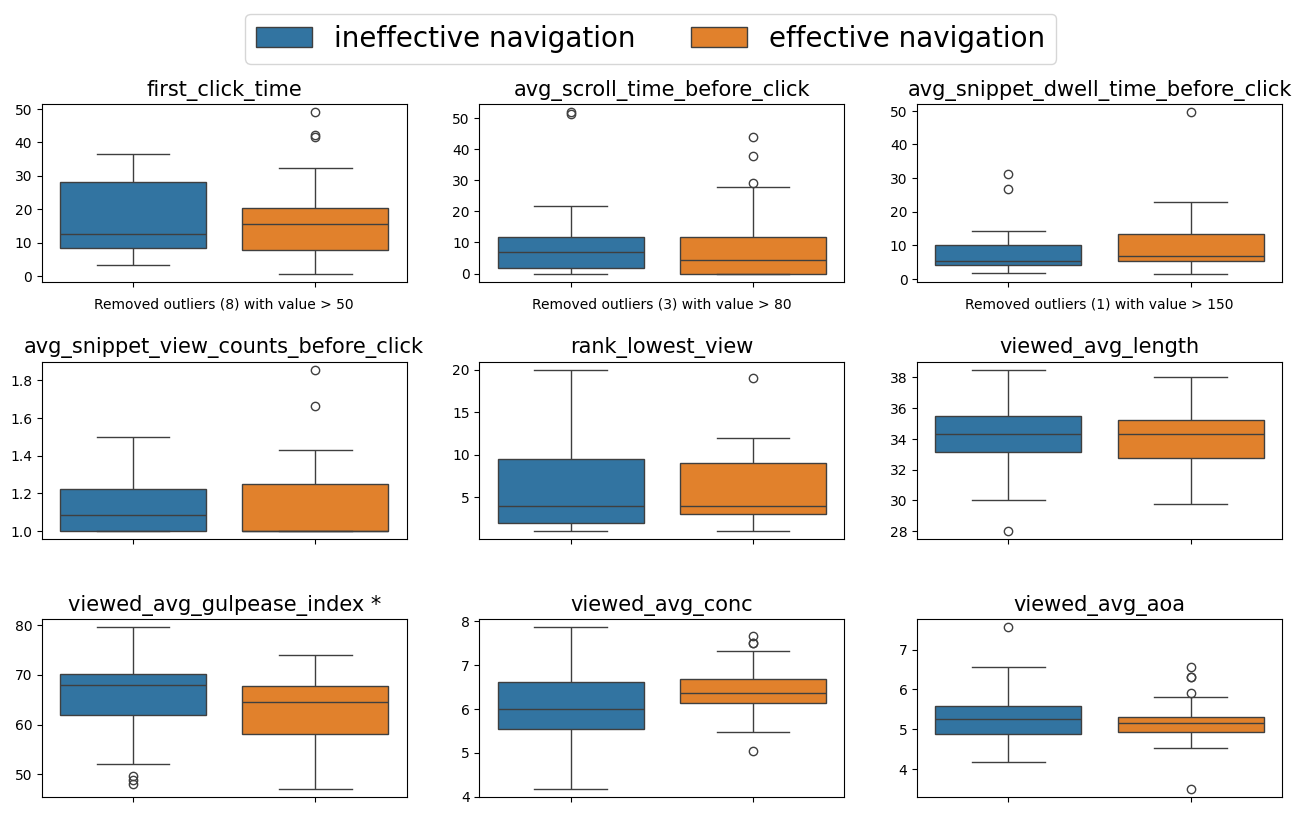

In [37]:
from driver import get_boxplots

get_boxplots(df=navigation_quality, search_stage="results_navigation_nav_eff", categories=categories, group="effective_nav", artefact="navigation", n_cols=3, n_rows=3, stats_df=sig_test_results_nav_eff)

In [38]:
from driver import get_significance

categories = [
    # "total_clicks", "repetitions", 
    "first_click_time", "avg_scroll_time_before_click", "avg_snippet_dwell_time_before_click", "avg_snippet_view_counts_before_click", "rank_lowest_view", 
    "viewed_avg_length", "viewed_avg_gulpease_index", "viewed_avg_conc", "viewed_avg_aoa",
    # "SERP_avg_length", "SERP_avg_gulpease_index", "SERP_avg_conc", "SERP_avg_aoa"
]

desc_stats_df_tail_ratio, sig_test_results_tail_ratio = get_significance(df=navigation_quality, effective_label="effective_nav_pt2", search_stage="results_navigation_tail_ratio", categories=categories)
sig_test_results_tail_ratio

,search_stage,characteristic,test_statistic,pval,significant
0,results_navigation_tail_ratio,first_click_time,2.146000,0.5652,False
1,results_navigation_tail_ratio,avg_scroll_time_before_click,-0.833067,0.7062,False
2,results_navigation_tail_ratio,avg_snippet_dwell_time_before_click,-1.736067,0.1646,False
3,results_navigation_tail_ratio,avg_snippet_view_counts_before_click,0.009722,0.9332,False
4,results_navigation_tail_ratio,rank_lowest_view,-3.500000,0.0278,True
5,results_navigation_tail_ratio,viewed_avg_length,0.750000,0.0840,False
6,results_navigation_tail_ratio,viewed_avg_gulpease_index,3.301815,0.0204,True
7,results_navigation_tail_ratio,viewed_avg_conc,-0.145194,0.5696,False
8,results_navigation_tail_ratio,viewed_avg_aoa,0.057833,0.5510,False


In [39]:
desc_stats_df_tail_ratio

,search_stage,characteristic,ineffective_median,ineffective_MAD,effective_median,effective_MAD
0,results_navigation_tail_ratio,first_click_time,21.026000,12.418500,18.880000,10.493000
1,results_navigation_tail_ratio,avg_scroll_time_before_click,6.826933,4.597300,7.660000,7.652000
2,results_navigation_tail_ratio,avg_snippet_dwell_time_before_click,5.079933,1.588311,6.816000,2.849435
3,results_navigation_tail_ratio,avg_snippet_view_counts_before_click,1.059722,0.050000,1.050000,0.050000
4,results_navigation_tail_ratio,rank_lowest_view,3.000000,1.000000,6.500000,3.500000
5,results_navigation_tail_ratio,viewed_avg_length,34.700000,1.448529,33.950000,1.121429
6,results_navigation_tail_ratio,viewed_avg_gulpease_index,68.041636,2.984955,64.739822,4.838926
7,results_navigation_tail_ratio,viewed_avg_conc,6.119097,0.592014,6.264292,0.310488
8,results_navigation_tail_ratio,viewed_avg_aoa,5.235867,0.426389,5.178033,0.253194


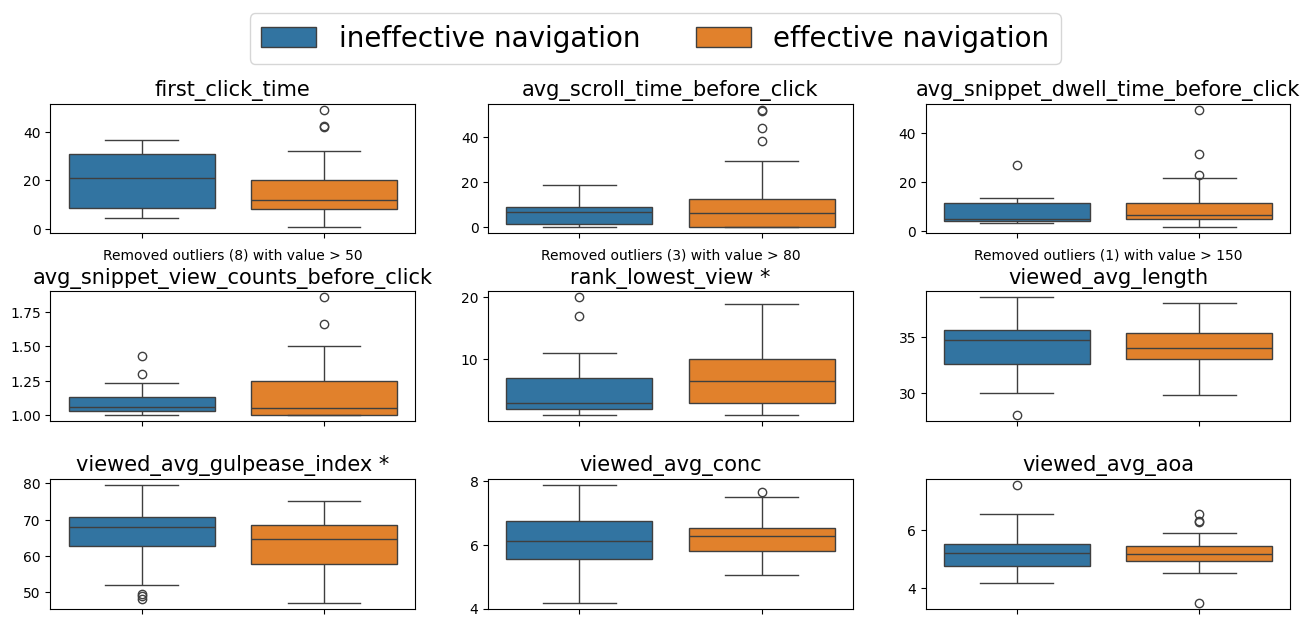

In [40]:
from driver import get_boxplots

get_boxplots(df=navigation_quality, search_stage="results_navigation_tail_ratio", categories=categories, group="effective_nav_pt2", artefact="navigation", n_cols=3, n_rows=4, stats_df=sig_test_results_tail_ratio)